In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [5]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import(
    confusion_matrix,
    classification_report,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    ConfusionMatrixDisplay,
    RocCurveDisplay
)

In [6]:
df=pd.read_csv("/content/creditcard.csv")
print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
print("\nFirst 5 rows:")
print(df.head())

Dataset loaded successfully!
Dataset shape: (19898, 31)

First 5 rows:
   Time        V1        V2        V3        V4        V5        V6        V7  \
0     0 -1.359807 -0.072781  2.536347  1.378155 -0.338321  0.462388  0.239599   
1     0  1.191857  0.266151  0.166480  0.448154  0.060018 -0.082361 -0.078803   
2     1 -1.358354 -1.340163  1.773209  0.379780 -0.503198  1.800499  0.791461   
3     1 -0.966272 -0.185226  1.792993 -0.863291 -0.010309  1.247203  0.237609   
4     2 -1.158233  0.877737  1.548718  0.403034 -0.407193  0.095921  0.592941   

         V8        V9  ...       V21       V22       V23       V24       V25  \
0  0.098698  0.363787  ... -0.018307  0.277838 -0.110474  0.066928  0.128539   
1  0.085102 -0.255425  ... -0.225775 -0.638672  0.101288 -0.339846  0.167170   
2  0.247676 -1.514654  ...  0.247998  0.771679  0.909412 -0.689281 -0.327642   
3  0.377436 -1.387024  ... -0.108300  0.005274 -0.190321 -1.175575  0.647376   
4 -0.270533  0.817739  ... -0.009431  0.79

In [7]:
print("\nDataset information:")
df.info()
print("\nMissing values:")
print(df.isnull().sum().sum())

print("\n Class Distribution:")
print(df["Class"].value_counts())

print("\nCategory percentages:")
print(df["Class"].value_counts(normalize=True)*100)


Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19898 entries, 0 to 19897
Data columns (total 31 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Time    19898 non-null  int64  
 1   V1      19898 non-null  float64
 2   V2      19898 non-null  float64
 3   V3      19898 non-null  float64
 4   V4      19898 non-null  float64
 5   V5      19898 non-null  float64
 6   V6      19898 non-null  float64
 7   V7      19898 non-null  float64
 8   V8      19898 non-null  float64
 9   V9      19898 non-null  float64
 10  V10     19898 non-null  float64
 11  V11     19897 non-null  float64
 12  V12     19897 non-null  float64
 13  V13     19897 non-null  float64
 14  V14     19897 non-null  float64
 15  V15     19897 non-null  float64
 16  V16     19897 non-null  float64
 17  V17     19897 non-null  float64
 18  V18     19897 non-null  float64
 19  V19     19897 non-null  float64
 20  V20     19897 non-null  float64
 21  V21     19897

In [8]:
X=df.drop("Class",axis=1)
y=df["Class"]
print("Feature shape:",X.shape)
print("Target shape:",y.shape)
print("\nFeatures:")
print(X.columns.tolist())

Feature shape: (19898, 30)
Target shape: (19898,)

Features:
['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount']


In [9]:

df_clean = df.dropna()
X_clean = df_clean.drop("Class", axis=1)
y_clean = df_clean["Class"]
X_train, X_test, y_train, y_test = train_test_split(
    X_clean,
    y_clean,
    test_size=0.20,
    random_state=42,
    stratify=y_clean
)
print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (15917, 30)
Testing data: (3980, 30)


In [10]:
model = RandomForestClassifier(
    n_estimators=100,
    class_weight="balanced_subsample",
    random_state=42,
    n_jobs=-1
)
print("Training Random FOrest model...")
model.fit(X_train,y_train)
print("Model training completed successfully!")

Training Random FOrest model...
Model training completed successfully!


In [11]:
y_pred=model.predict(X_test)
y_prob=model.predict_proba(X_test)[:,1]
print("Actual labels:")
print(y_test.head(20))
print(("Predicted labels:"))
print(y_pred[:20])

Actual labels:
13745    0.0
4265     0.0
10183    0.0
4859     0.0
9917     0.0
1405     0.0
11644    0.0
16961    0.0
5478     0.0
1230     0.0
6456     0.0
16075    0.0
17106    0.0
5929     0.0
8093     0.0
19087    0.0
10236    0.0
5290     0.0
12788    0.0
15710    0.0
Name: Class, dtype: float64
Predicted labels:
[0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]


In [12]:

cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[3961    2]
 [   6   11]]


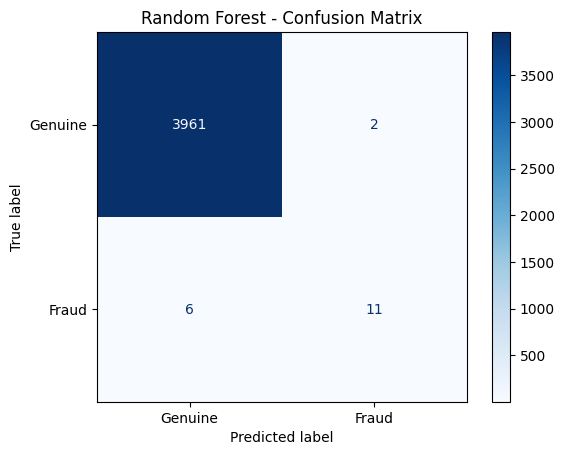

Precision : 0.8462
Recall    : 0.6471
F1-score  : 0.7333
ROC-AUC   : 0.9398

Detailed Classification Report:
              precision    recall  f1-score   support

     Genuine       1.00      1.00      1.00      3963
       Fraud       0.85      0.65      0.73        17

    accuracy                           1.00      3980
   macro avg       0.92      0.82      0.87      3980
weighted avg       1.00      1.00      1.00      3980



In [13]:
ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Genuine", "Fraud"]
).plot(cmap="Blues", values_format="d")

plt.title("Random Forest - Confusion Matrix")
plt.show()

precision = precision_score(
    y_test, y_pred, zero_division=0
)
recall = recall_score(
    y_test, y_pred, zero_division=0
)
f1 = f1_score(
    y_test, y_pred, zero_division=0
)
roc_auc = roc_auc_score(y_test, y_prob)
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1-score  : {f1:.4f}")
print(f"ROC-AUC   : {roc_auc:.4f}")
print("\nDetailed Classification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        target_names=["Genuine", "Fraud"],
        zero_division=0
    )
)

In [14]:
results = X_test.copy()
results["Actual"] = y_test
results["Predicted"] = y_pred
results["Fraud_Probability"] = y_prob

actual_fraud = results[results["Actual"] == 1]

print("Total actual fraud cases:", len(actual_fraud))
print(actual_fraud[["Time", "Amount", "Actual", "Predicted", "Fraud_Probability"]].head(20))

print("Fraud detected:", len(results[(results["Actual"] == 1) & (results["Predicted"] == 1)]))
print("Fraud missed:", len(results[(results["Actual"] == 1) & (results["Predicted"] == 0)]))

actual_fraud.to_csv("actual_fraudulent_test_transactions.csv", index=True)
print("File saved successfully!")

Total actual fraud cases: 17
        Time   Amount  Actual  Predicted  Fraud_Probability
18472  29531     0.68     1.0        0.0               0.34
14211  25254    99.99     1.0        1.0               0.88
6774    8528     1.00     1.0        1.0               0.97
8296   11080     1.00     1.0        1.0               0.59
6899    8878     1.00     1.0        1.0               0.98
16780  28143    99.99     1.0        1.0               0.94
6338    7551     1.00     1.0        1.0               0.79
10484  17187     3.79     1.0        0.0               0.00
8617   11635     1.00     1.0        1.0               0.75
6329    7519     1.00     1.0        0.0               0.26
9487   14073     1.00     1.0        1.0               0.97
14104  25095     3.12     1.0        0.0               0.04
6971    9064  1809.68     1.0        0.0               0.34
11880  20451     1.00     1.0        1.0               0.99
10497  17220     3.79     1.0        0.0               0.00
15566  2696

Top 10 Important Features:
V14    0.191935
V3     0.126382
V17    0.101573
V10    0.096047
V12    0.086816
V2     0.070369
V11    0.063085
V4     0.059853
V16    0.057967
V6     0.022832
dtype: float64


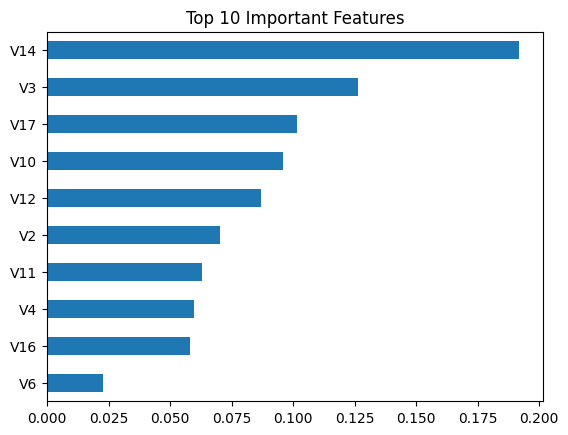

In [15]:
importance = pd.Series(model.feature_importances_, index=X.columns)

top10 = importance.nlargest(10)
print("Top 10 Important Features:")
print(top10)

top10.sort_values().plot(kind="barh")
plt.title("Top 10 Important Features")
plt.show()


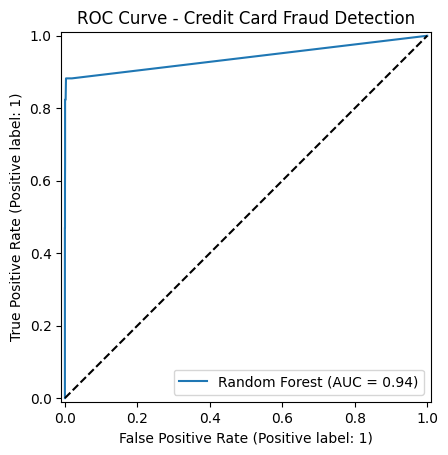

In [16]:
RocCurveDisplay.from_predictions(
    y_test,
    y_prob,
    name="Random Forest"
)
plt.title("ROC Curve - Credit Card Fraud Detection")
plt.plot([0, 1], [0, 1], "k--")
plt.show()